In [2]:

import numpy as np
import pandas as pd
import rioxarray as rxr
from osgeo import gdal
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline, make_pipeline

import geopandas as gpd
import rasterio
from shapely.geometry import box
import pandas as pd
from shapely.geometry import Point
from rasterio.sample import sample_gen


In [3]:
path = 'G:\ICESat-2\Region2_map\wash_bay_map\A2022\wash_bay_2022_sample_points_final.shp'
output = 'G:\ICESat-2\Region2_map\wash_bay_map\A2022\wash_bay_2022_sample_points_final.csv'
k = gpd.read_file(path)
k.to_csv(output)

In [ ]:
x = [10, 20, 30, 40, 50 ,60, 70, 80, 90, 98]
y1 = [0.551, 0.308, 0.377, 0.343, 0.347, 0.333, 0.330, 0.310, 0.303, 0.298]
y2 = [0.390, 0.418, 0.274, 0.251, 0.250, 0.240, 0.233, 0.217, 0.215, 0.208]
y3 = [0.807, 0.888, 0.910, 0.927, 0.925, 0.932, 0.932, 0.941, 0.945, 0.946]

In [2]:
def save_img(output_filename, reference_filename, array):
    # 打开参考数据
    reference = gdal.Open(reference_filename)
    
    # 获取地理变换参数和坐标系
    geo_transform = reference.GetGeoTransform()
    projection = reference.GetProjection()

    # 获取矩阵尺寸
    rows, cols = array.shape

    # 创建新的 TIFF 数据集
    driver = gdal.GetDriverByName('GTiff')
    out_data = driver.Create(output_filename, cols, rows, 1, gdal.GDT_Float32)

    # 设置地理变换和坐标系
    out_data.SetGeoTransform(geo_transform)
    out_data.SetProjection(projection)
    

    # 写入数据
    out_data.GetRasterBand(1).WriteArray(array)

    # 保存并关闭文件
    out_data.FlushCache()
    out_data = None

In [63]:

location = 'wash_bay'
region = 'Region2'
input_bands = 'all_bands'
Freq = '10'
# input_bands = 'Freq'
method = 'RF'#,'RF','Poly, MpLinear', 'MpPoly'
year = 2022

csv_path = f'G:\ICESat-2\{region}\{region}_{location}\A_{location}_30m_{year}_new10.csv'
shp_path = f'G:\ICESat-2\{region}_map\{location}_map\A2022\A_{location}_30m_{year}_new10.shp'
osgm_path = 'G:\OSGM15\Great_Britain_osgm15.tif'
#raster_path = f'G:\ICESat-2\{region}_map\{location}_map\Discuss_test\{location}_{year}_FB6_new2_{Freq}.tif'
raster_path = f'G:\ICESat-2\Discussion5_2\Raw_image\Wash_2022_FB6_new2_{Freq}.tif'

df = pd.read_csv(csv_path)
# df = gpd.read_file(shp_path)
lon, lat = 'mean_lon', 'mean_lat'
print(df.shape)
print(df.columns)

geometry = [Point(xy) for xy in zip(df[lon], df[lat])]
gdf = gpd.GeoDataFrame(df, geometry=geometry)
gdf.set_crs(epsg=4326, inplace=True)
# 读取点数据
points = gdf#//gpd.read_file(output_)

# load FB6
with rasterio.open(raster_path) as src:
    # 1. 检查坐标系
    if points.crs != src.crs:
        points = points.to_crs(src.crs)
    coords = [(point.x, point.y) for point in points.geometry]
    values = list(src.sample(coords))

    # 添加波段值到属性表
    band_count = src.count
    for band in range(band_count):
        points[f"b{band + 1}_FB6"] = [v[band] for v in values]

#load osgm_path
with rasterio.open(osgm_path) as src:

    if points.crs != src.crs:
        points = points.to_crs(src.crs)
    coords = [(point.x, point.y) for point in points.geometry]
    values = list(src.sample(coords))

    band_count = src.count
    for band in range(band_count):
        points[f"b{band + 1}_osgb36"] = [v[band] for v in values]

    #points['OH'] = points['mean_height'] - points['b1_osgb36'] 
    points['OH'] = points['mean_heigh'] - points['b1_osgb36'] 
    # 保存为新的 shapefile

#icesat_mask = (points['OH'] < 5) & (points['b7_FB6'] > 0)  
icesat_mask = (points['OH'] < 5) & (points['b5_FB6'] > 0) # & (points['b6_FB6'] < 0.95)
data = points[icesat_mask]
data.shape

(2973, 17)
Index(['Unnamed: 0', 'Unnamed_ 0', 'distance', 'mean_heigh', 'mean_lon',
       'mean_lat', 'OSGM', 'OH', 'Strip_No', 'b1_FB6', 'b2_FB6', 'b3_FB6',
       'b4_FB6', 'b5_FB6', 'b6_FB6', 'LULC', 'geometry'],
      dtype='object')


(2825, 18)

In [ ]:

#extract y_train and x_train data
if input_bands == 'all_bands':

    target_band = ['b1_FB6']#,'b2_FB6','b3_FB6','b4_FB6']#, 'b7_FB2']
    target_id = [0]#, 1, 2, 3]#, 4, 5] #
    
    # target_band = ['b1_FB6',  'b2_FB6']#,'b5_FB2', 'b6_FB2', 'b7_FB2']
    # target_id = [0, 1]#, 4, 5] #

    #output_path = f'G:\ICESat-2\{region}_map\{location}_map\Discuss_test\Retrieval_DTM\{location}_{year}_1_3_{method}_FB6_new10_{Freq}.tif'
    output_path = f'G:\ICESat-2\Discussion5_2\Retrieved_DTM\{location}_{year}_1_{method}_FB6_new10_{Freq}.tif'
    
else:
    target_band = ['b1_FB6'] # ['b1_ribble_']# ['b1_Morecam']#[f'b1_{location}_']4
    target_id = [0]    
    output_path = f'G:\ICESat-2\{region}_map\{location}_map\Discuss_test\Retrieval_DTM\{location}_{year}_1_{method}_FB6_new10_{Freq}.tif'


y_train = data['OH'].values
x_train = data[target_band].values
print('x_train:', x_train.shape)
print('y_train', y_train.shape)

#select calssifer
if method == 'RF':
    #classifier = RandomForestRegressor(n_estimators=300, random_state=30)
    classifier = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=30)
    #classifier = RandomForestRegressor(n_estimators=300, max_depth=15, random_state=30)
    classifier.fit(x_train, y_train)
elif method == 'Linear':
    classifier = np.polyfit(x_train[:, 0], y_train, deg=1)
elif method == 'Poly':
    classifier = np.polyfit(x_train[:, 0], y_train, deg=2)
elif method == 'MpLinear':
    classifier = LinearRegression()
    classifier.fit(x_train, y_train)
elif method == 'MpPoly':
    degree = 3  # 设置多项式的阶数
    classifier = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    classifier.fit(x_train, y_train)
    # classifier = PolynomialFeatures()
    # classifier.fit(x_train, y_train)
else:
    print('error classifier input')

# # load Ramdon Forest classifer
# rf_regressor = RandomForestRegressor(n_estimators=100, random_state=30)
# rf_regressor.fit(x_train, y_train)

#load raster 

#raster_path = f'G:\ICESat-2\{region}_map\{location}_map\Discuss_test\{location}_{year}_FB6_new2_{Freq}.tif'
raster_path = f'G:\ICESat-2\Discussion5_2\Raw_image\Wash_2022_FB6_new2_{Freq}.tif'

raster = rxr.open_rasterio(raster_path).values
raster = np.nan_to_num(raster, nan = 0)
selected_raster = raster[target_id, :, :]

if len(selected_raster.shape) != 3:
    row, col = selected_raster.shape
    selected_raster = selected_raster.reshape(1, row, col)
else: 
    bands, row, col = selected_raster.shape

print('selected_raster.shape', selected_raster.shape)

x_train: (2825, 1)
y_train (2825,)
selected_raster.shape (1, 1511, 2844)


In [65]:
# Topograph mapping 

k = 0
result = np.array([[]])
for i in range(row):
    
    x_train = np.transpose(selected_raster[:, i, :])
    if method == 'RF':
        y_pred = classifier.predict(x_train)
    elif  method == 'Linear' :
        y_pred = np.polyval(classifier, x_train)
    elif  method == 'Poly' :
        y_pred = np.polyval(classifier, x_train)
    elif method == 'MpLinear':
        y_pred = classifier.predict(x_train)
    elif method == 'MpPoly':
        
        y_pred = classifier.predict(x_train)

    result = np.append(result, y_pred)
    if i%(int(row/5)) == 0:
        
        print(k*20 , '%_ is done')
        k = k+1

print(result.shape, type(result))

tf_mask = raster[4,:,:].flatten()
Freq_s2 = raster[5,:,:].flatten()
result[(tf_mask == 0) | (Freq_s2 > 0.95)] = 0
result_ = result.reshape(row, col)

save_img(output_path, raster_path, result_)


0 %_ is done
20 %_ is done
40 %_ is done
60 %_ is done
80 %_ is done
100 %_ is done
(4297284,) <class 'numpy.ndarray'>


In [32]:
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
from rasterio.transform import from_origin
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.geometry import box
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.stats import pearsonr
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
validation_path = 'G:\ICESat-2\Discussion5_1\Validation_point\Validation_2022_Ribble1.shp'
validation_path = 'G:\ICESat-2\Discussion5_1\Validation_point\wash_bay_2022_sample_points.shp'
z = gpd.read_file(validation_path)
z = pd.DataFrame(z)
z.columns

Index(['Refer_dem', 'retrieved_', 'RF2', 'RF1', 'RF', 'RF3', 'RW1_dtm',
       'RF_raw', 'RW2_dtm', 'DTM_1_RF', 'DTM_2_RF', 'DTM_3_RF', 'DTM_4_RF',
       'DTM_RF_20', 'DTM_RF_40', 'DTM_RF_60', 'DTM_RF_80', 'DTM_Linear',
       'DTM_Poly', 'D1924_4_', 'D1924_1_', 'geometry'],
      dtype='object')

In [ ]:
#----------------------------- Validation ---------------------------
year = 2022
validation_path = 'G:\ICESat-2\Discussion5_1\Validation_point\Validation_2022_Ribble1.shp'
location2 = 'DTM_Linear'
output_path = f'G:/ICESat-2/Retrieval_DTM_validation/discuss_plot/{location2}_4_RF.png'
z = gpd.read_file(validation_path)
z = pd.DataFrame(z)
z = z.dropna()
z = z[(z['Refer_dem'] != 0) & (z[location2] != 0) & (z['D1924_1_'] != 0)] #& (z['Freq80_4_R'] != 0) & (z['Freq60_4_R'] != 0)& (z['Freq40_4_R'] != 0)& (z['Freq20_4_R'] != 0)

x = z['Refer_dem']
y = z[location2]
y = np.array(y)
x = np.array(x)

R, _ = pearsonr(y, x)
R2 = r2_score(y, x)
MAD = np.mean(np.abs(y-x))
MSB = np.mean((y-x))
RMSE = np.sqrt(np.mean((y-x)**2))
num = int(len(x))


xy = np.vstack([x,y])  #  将两个维度的数据叠加
z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

# Sort the points by density, so that the densest points are plotted last
idx = z.argsort()
x, y, z = x[idx], y[idx], z[idx]

fig, ax = plt.subplots()
textstr = f"R² = {R2:.2f}\nMAE = {MAD:.3f}\nRMSE = {RMSE:.3f} \nN = {num}"
name = f'{location2} ({year})'
ax.text(0.05, 0.95, textstr, transform = ax.transAxes, fontsize = 16, verticalalignment = 'top')
ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

ax.set_xlabel('Reference dem', fontsize = 15)
ax.set_ylabel('Retrieved dem', fontsize = 15)
ax.plot([-3, 6], [-3, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)
sc = plt.scatter(y, x, c=z, s=5, cmap='Spectral_r', zorder=2)
cbar = plt.colorbar(sc)

# plt.scatter(x, y,c=z, s=2,cmap='Spectral_r') # c表示标记的颜色
# plt.colorbar()

ax.set_xlim(-3, 4)
ax.set_ylim(-3, 4)
ax.tick_params(axis='both', labelsize=12)
# plt.savefig(output_path, dpi=300, bbox_inches='tight')
plt.show()

In [64]:
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
from rasterio.transform import from_origin
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.geometry import box
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.stats import pearsonr
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np

validation_path = f'G:\ICESat-2\Discussion5_1\Validation_point\Ribble_2022_sample_points.shp'
z = gpd.read_file(validation_path)
z = pd.DataFrame(z)
print(z.shape)
z.columns


(762, 23)


Index(['Refer_dem', 'retrieved_', 'RR_dtm', 'RR2_dtm', 'Raw_dtm', 'Ref_dtm',
       'DTM_1_RF', 'DTM_2_RF', 'DTM_3_RF', 'DTM_4_RF', 'DTM_RF_20',
       'DTM_RF_40', 'DTM_RF_60', 'DTM_RF_80', 'DTM_Linear', 'DTM_Poly',
       'Minus_tif2', 'Minus_tif1', 'DTM_02_RF', 'DTM_Freq_R', 'DTM_red_RF',
       'DTM_nir_RF', 'geometry'],
      dtype='object')

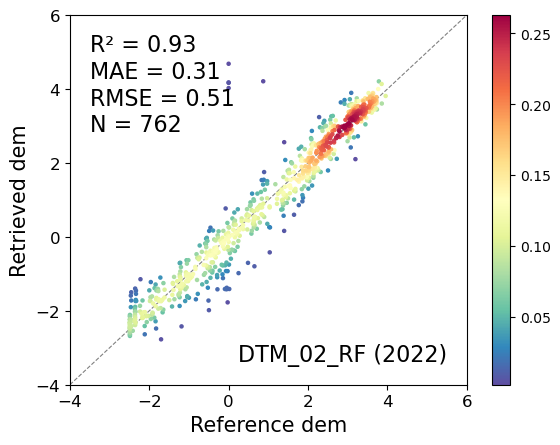

In [32]:
#----------------------------- Validation ---------------------------

validation_path =  f'G:\ICESat-2\Discussion5_1\Validation_point\Ribble_2022_sample_points.shp'
#f'G:\ICESat-2\Discussion5_1\Validation_point\Thames_2019_sample_points.shp'
location = 'Ribble_c'
location2 = 'DTM_02_RF'
year = 2022

output_path = f'G:\ICESat-2\Discussion5_1\FIG/{location}_{location2}.png'
z = gpd.read_file(validation_path)
z = pd.DataFrame(z)
z = z.dropna()

#z = z[(z['Refer_dem'] != 0) & (z['RF3_4'] != 0) & (z['RF_4'] != 0) & (z['RF3_1'] != 0)& (z['Linear_1'] != 0)& (z['RF2_1'] != 0)& (z['RF1_1'] != 0)]

x = z['Refer_dem']
y = z[location2]
y = np.array(y)
x = np.array(x)

R, _ = pearsonr(y, x)
R2 = r2_score(x, y)
MAD = np.mean(np.abs(y-x))
MSB = np.mean((y-x))
RMSE = np.sqrt(np.mean((y-x)**2))
num = int(len(x))


xy = np.vstack([x,y])  #  将两个维度的数据叠加
z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

# Sort the points by density, so that the densest points are plotted last
idx = z.argsort()
x, y, z = x[idx], y[idx], z[idx]

fig, ax = plt.subplots()
textstr = f"R² = {R2:.2f}\nMAE = {MAD:.2f}\nRMSE = {RMSE:.2f} \nN = {num}"
name = f'{location2} ({year})'
ax.text(0.05, 0.95, textstr, transform = ax.transAxes, fontsize = 16, verticalalignment = 'top')
ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

ax.set_xlabel('Reference dem', fontsize = 15)
ax.set_ylabel('Retrieved dem', fontsize = 15)
ax.plot([-4, 6], [-4, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)
sc = plt.scatter(y, x, c=z, s=5, cmap='Spectral_r', zorder=2)
cbar = plt.colorbar(sc)

# plt.scatter(x, y,c=z, s=2,cmap='Spectral_r') # c表示标记的颜色
# plt.colorbar()

ax.set_xlim(-4, 6)
ax.set_ylim(-4, 6)
ax.tick_params(axis='both', labelsize=12)
plt.savefig(output_path, dpi=300, bbox_inches='tight')

In [56]:
ICESAT_path = 'G:\ICESat-2\Discussion5_1\ICESAT\A_Ribble_c_30m_2022_new10.shp'
ICESAT_path = 'G:\ICESat-2\Discussion5_1\ICESAT\Ref_Ribble_c_2022_sample_points.shp'
points = gpd.read_file(ICESAT_path)
print(points.columns)

#icesat_mask = (points['OH'] < 5) & (points['b5_FB6'] > 0)  & (points['Ref_dtm'] != 6) & (points['Ref_dtm'] != -9999) 
#icesat_mask = (points['OH'] < 5) & (points['b5_FB6'] > 0)  & (points['Wash_refer'] != 6) & (points['Wash_refer'] != -9999) 
data = points[icesat_mask]
# points.shape
# data = points
print(data.shape)
data.columns


Index(['Refer_dem', 'retrieved_', 'b1_FB6', 'b2_FB6', 'b3_FB6', 'b4_FB6',
       'Ref_dtm', 'geometry'],
      dtype='object')
(1347, 8)


c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\geopandas\geodataframe.py:1750: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)


Index(['Refer_dem', 'retrieved_', 'b1_FB6', 'b2_FB6', 'b3_FB6', 'b4_FB6',
       'Ref_dtm', 'geometry'],
      dtype='object')

In [62]:

#extract y_train and x_train data
method = 'RF'
year = 2022
region = 'Ribble'
band = 4

for j in range(1, 2):
    
    # band = i*20
    # target_band_list, target_id_list = [f'b1_FB6_{band}',f'b2_FB6_{band}',f'b3_FB6_{band}',f'b4_FB6_{band}'], [0, 1, 2, 3]
    # target_band, target_id = target_band_list[:4], target_id_list[:4]
        
    target_band = ['b1_FB6', 'b2_FB6', 'b3_FB6', 'b4_FB6']#,  'b4_FB6']#,'b5_FB2', 'b6_FB2', 'b7_FB2']
    target_id = [0, 1, 2, 3]#, 3]#, 4, 5] #
    

        #output_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year}\{location}_{year}_4_{method}_FB6_new10.tif'
    #output_path = f'G:\ICESat-2\Discussion5_1\Retrival_DTM\{location}_{year}_4_{method}3_FB6_new10.tif'
    #output_path = f'G:\ICESat-2\Discussion5_1\Retrival_DTM\{region}\{region}_{year}_4_{method}_FB6_new10_{band}.tif'
    output_path = f'G:\ICESat-2\Discussion5_1\Method_discuss\{region}\Ref_{region}_{year}_{band}_{method}_FB6_new10.tif'

    #y_train = data['OH'].values
    y_train = data['Ref_dtm'].values
    x_train = data[target_band].values
    print('x_train:', x_train.shape)
    print('y_train', y_train.shape)

    # print(np.max(x_train), np.min(x_train))
    # print(np.any(np.isnan(x_train)), np.any(np.isinf(x_train)))
    # print(np.max(selected_raster), np.min(selected_raster))
    #select calssifer
    if method == 'RF':
        classifier = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=30)
        #classifier = RandomForestRegressor(n_estimators=300, min_samples_leaf=20, random_state=30)
        #classifier = RandomForestRegressor(n_estimators=300, max_depth=15, random_state=30)
        classifier.fit(x_train, y_train)
    elif method == 'Linear':
        classifier = np.polyfit(x_train[:, 0], y_train, deg=1)
    elif method == 'Poly':
        classifier = np.polyfit(x_train[:, 0], y_train, deg=2)
    elif method == 'MpLinear':
        classifier = LinearRegression()
        classifier.fit(x_train, y_train)
    elif method == 'MpPoly':
        degree = 3  # 设置多项式的阶数
        classifier = make_pipeline(PolynomialFeatures(degree), LinearRegression())
        classifier.fit(x_train, y_train)
        # classifier = PolynomialFeatures()
        # classifier.fit(x_train, y_train)
    else:
        print('error classifier input')

    # # load Ramdon Forest classifer
    # rf_regressor = RandomForestRegressor(n_estimators=100, random_state=30)
    # rf_regressor.fit(x_train, y_train)

    #load raster 


    raster_path = f'G:\ICESat-2\Discussion5_1\Retrival_DTM\Ribble_c_{year}_FB6_new2.tif'
    #raster_path = f'G:\ICESat-2\Discussion5_1\Input_num_discuss\Ribble\Ribble_2022_FB6_new2_{band}.tif'

    raster = rxr.open_rasterio(raster_path).values
    # raster = np.nan_to_num(raster, nan = 0)
    # selected_raster = raster[target_id, :, :]

    selected_raster = raster[target_id, :, :]

    # 定义 NoData 值（可调整，视数据源而定）
    NODATA_THRESHOLD = -1e10

    # 将异常值统一转换为 np.nan（以便后续掩膜）
    selected_raster_clean = selected_raster.astype('float32')  # 避免整数不能装 nan
    selected_raster_clean[selected_raster_clean < NODATA_THRESHOLD] = np.nan
    selected_raster = selected_raster_clean
#-----------------------------------------------------------


    if len(selected_raster.shape) != 3:
        row, col = selected_raster.shape
        selected_raster = selected_raster.reshape(1, row, col)
    else: 
        bands, row, col = selected_raster.shape

    print('selected_raster.shape', selected_raster.shape)

    # Topograph mapping 

    k = 0
    result = np.array([[]])
    for i in range(row):
        
        x_train = np.transpose(selected_raster[:, i, :])
        if method == 'RF':
            y_pred = classifier.predict(x_train)
        elif  method == 'Linear' :
            y_pred = np.polyval(classifier, x_train)
        elif  method == 'Poly' :
            y_pred = np.polyval(classifier, x_train)
        elif method == 'MpLinear':
            y_pred = classifier.predict(x_train)
        elif method == 'MpPoly':
            
            y_pred = classifier.predict(x_train)

        result = np.append(result, y_pred)
        if i%(int(row/5)) == 0:
            
            print(k*20 , '%_ is done')
            k = k+1

    print(result.shape, type(result))

    tf_mask = raster[4,:,:].flatten()
    Freq_s2 = raster[5,:,:].flatten()
    result[(tf_mask == 0) | (Freq_s2 > 0.95)] = 0
    result_ = result.reshape(row, col)

    save_img(output_path, raster_path, result_)

x_train: (1347, 4)
y_train (1347,)
selected_raster.shape (4, 942, 813)
0 %_ is done
20 %_ is done
40 %_ is done
60 %_ is done
80 %_ is done
100 %_ is done
(765846,) <class 'numpy.ndarray'>


In [31]:
classifier.feature_importances_


array([1.])

In [63]:
region ='Ribble'
year = 2022
method = 'RF'
#validation_path = f'G:\ICESat-2\Discussion5_1\Validation_point\{region}_{year}_sample_points.shp'
validation_path = f'G:\ICESat-2\Discussion5_1\Validation_point\Validation_2022_Ribble1.shp'
points = gpd.read_file(validation_path)

for i in range(1,5):
    band = i
    val_name = f'RDTM_{band}_{method}'
    #Extracted_path = f'G:\ICESat-2\Discussion5_1\Retrival_DTM\wash_bay\wash_bay_2022_4_RF_FB6_new10_{band}.tif'
    #Extracted_path = f'G:\ICESat-2\Discussion5_1\Method_discuss\{region}\{region}_{year}_4_{method}_FB6_new10.tif'
    Extracted_path =  f'G:\ICESat-2\Discussion5_1\Method_discuss\{region}\Ref_{region}_{year}_{band}_{method}_FB6_new10.tif'

    with rasterio.open(Extracted_path) as src:
        raster_crs = src.crs  # 获取 raster 的坐标系
        
        # 3. 如果坐标系不同，则重投影点数据
        if points.crs != raster_crs:
        # print(f"坐标系不一致，正在从 {points.crs} 转换为 {raster_crs}")
            points = points.to_crs(raster_crs)

        # 4. 获取坐标并提取像元值（默认波段 1）
        coords = [(geom.x, geom.y) for geom in points.geometry]
        values = [val[0] for val in src.sample(coords)]
    points[val_name] = values
points.to_file(validation_path)

In [329]:
validation_path = 'G:\ICESat-2\Discussion5_1\ICESAT\A_Ribble_c_30m_2022_new10.shp'
points = gpd.read_file(validation_path)

for i in range(1,5):
    band = i*20
    val_name = f'DTM_{band}_RF'
    Extracted_path = f'G:\ICESat-2\Discussion5_1\Input_num_discuss\Ribble\Ribble_2022_FB6_new2_{band}.tif'

    with rasterio.open(Extracted_path) as src:
        raster_crs = src.crs  # 获取 raster 的坐标系
        
        # 3. 如果坐标系不同，则重投影点数据
        if points.crs != raster_crs:
        # print(f"坐标系不一致，正在从 {points.crs} 转换为 {raster_crs}")
            points = points.to_crs(raster_crs)

        # 4. 获取坐标并提取像元值（默认波段 1）
        coords = [(geom.x, geom.y) for geom in points.geometry]
        values = list(src.sample(coords)) #[val[0] for val in src.sample(coords)]
        
        for j in range(4):
            points[f"b{j+1}_FB6_{band}"] = [v[j] for v in values]
        
        
    # points[val_name] = values
points.to_file(validation_path)

In [331]:
k = gpd.read_file(validation_path)
k.columns

Index(['Unnamed__0', 'distance', 'mean_heigh', 'mean_lon', 'mean_lat', 'OSGM',
       'OH', 'Strip_No', 'b1_FB6', 'b2_FB6', 'b3_FB6', 'b4_FB6', 'b5_FB6',
       'b6_FB6', 'LULC', 'Ref_dtm', 'b1_FB6_20', 'b2_FB6_20', 'b3_FB6_20',
       'b4_FB6_20', 'b1_FB6_40', 'b2_FB6_40', 'b3_FB6_40', 'b4_FB6_40',
       'b1_FB6_60', 'b2_FB6_60', 'b3_FB6_60', 'b4_FB6_60', 'b1_FB6_80',
       'b2_FB6_80', 'b3_FB6_80', 'b4_FB6_80', 'geometry'],
      dtype='object')